# Body fat: measured specification judgments

`modeler_loop` tests proposed formula changes on shared training folds and
records each candidate, score and decision. This case predicts body fat measured by DEXA (dual-energy X-ray absorptiometry) from age, waist and hip
circumference, proposes removing a redundant measurement, and checks whether the
training folds support that change. It shows how to submit a proposed removal to `modeler_loop`, retain a required
predictor with `locks`, and use the returned fitted model. An extension connects the same
judgment interface, the function argument through which a proposer supplies edits, to a
live large language model (LLM).

The data contain 71 women from `TH.data`, used in the mboost tutorial
{cite:p}`hofner2014mboost_tutorial`. `DEXfat` is fat mass in kg, `age` is in years,
and the two circumferences are in cm. Age describes the person; the circumferences
measure related aspects of body size and composition. All three are available
before DEXA prediction. Their fitted associations can include shared causes and
cannot be read as effects of changing a circumference.

:::{admonition} Study design
:class: dropdown
Each row is one woman, treated as an independent sampling unit. The predictive
target and estimand are mean squared error in kg² for another woman from the same
population. A fixed split reserves 18 women for final evaluation; 53 women supply
five random folds for tuning and search. The test standard error is conditional
on the fitted model and reflects only variation among the 18 test losses.
Uncertainty from retraining and choosing a specification is not included.
:::

## Measurements and split

The three predictors are chosen before any search score is inspected. Keeping waist
circumference is a specification constraint chosen for this exercise; it makes no
claim that waist is a necessary causal adjustment.

In [1]:
import json
import altair as alt
import numpy as np
import polars as pl
from IPython.display import display

import mboostrs as mb
from bench_tables import table

alt.renderers.enable("svg")
bodyfat = mb.datasets.bodyfat(output="polars").select("DEXfat", "age", "waistcirc", "hipcirc")
order = np.random.default_rng(2026).permutation(bodyfat.height)
train, test = bodyfat[order[:53]], bodyfat[order[53:]]
display(train.head())

DEXfat,age,waistcirc,hipcirc
f64,i64,f64,f64
20.84,27,66.5,100.0
46.99,57,117.0,116.0
42.01,49,100.5,112.0
42.76,62,103.0,125.0
13.7,19,68.0,88.0


## Tuned baseline

The baseline uses linear effects of all three measurements. `Gaussian()` fixes
squared-error fitting for fat mass, `folds=5, seed=4` sets the random training
folds, and `nu=0.3` gives the learning rate used by the search below. `start=100`
is the first upper limit of the stopping-iteration search: the cross-validated risk
is read at every boosting iteration up to this limit to choose the number of
iterations, and the limit is doubled if the minimum lies at its end. The returned
`model` is ready to predict.

In [2]:
baseline = mb.tune_mstop(
    "DEXfat ~ bols(age) + bols(waistcirc) + bols(hipcirc)", train, mb.Gaussian(),
    score="mse", folds=5, seed=4, nu=0.3, start=100,
)
print(f"Baseline stopping iteration: {baseline.mstop}")

Baseline stopping iteration: 12


## Domain proposal

Waist and hip measurements overlap in what they describe, so the proposal tests
whether hip circumference can be omitted. The proposer is a callback, a Python
function that `modeler_loop` calls once per round with a report of the current
model and that returns a proposed edit. This callback is a fixed rule written by
hand: it always proposes dropping hip circumference. It exercises the judgment
interface offline and provides no evidence about the reasoning of a language
model. Copying the current `evidence_id` records which report of the current model
was used to propose the change. `drop` names the column whose terms would be
removed; the loop measures the resulting candidate before choosing it.

In [3]:
def measurement_judgment(digest):
    return mb.SpecificationJudgment(
        drop=("hipcirc",),
        evidence_id=digest["evidence_id"],
        reasoning=("Waist and hip measure related body size; test whether "
                   "the hip measurement is dispensable."),
    ).to_dict()

## Search rules

The loop finds candidate terms, measures their contribution, passes a digest
(a short summary of the measured report) to the proposer, validates proposed
edits and compares complete specifications. All comparisons in this Gaussian
example use squared prediction error on five shared random training folds. For
each candidate, the per-fold differences from the current formula give a mean
change and its paired fold standard error, the standard error of those five
differences. A larger specification needs an improvement of more than two paired
fold standard errors. A removal can be accepted when its loss is lower or its
increase is less than two standard errors. This explicit preference for a smaller
model is a search heuristic and does not test equivalence.

`locks=("waistcirc",)` prevents removing waist circumference. `budget=30` caps
the probe fits, the fits the initial automatic search (`autospec`) uses to score
candidate terms; `workflow_budget` caps all mboostrs model fits of the loop,
including comparisons and final tuning. `max_rounds=2` bounds the number of
proposal rounds, and `preexploration="dual"` lets a preliminary boosted-tree
ensemble and a small neural network propose candidate terms when the probe
allowance permits them. The live-provider extension uses these same inputs.

In [4]:
search = mb.modeler_loop(
    train, "DEXfat", family=mb.Gaussian(), judgment=measurement_judgment,
    domain_context=("DEXA fat in kg; age in years, waist and hip in cm. "
                    "Predictive associations only."),
    locks=("waistcirc",), budget=30, max_rounds=2, mstop=100,
    tune_start=100, seed=4, preexploration="dual",
    workflow_budget=mb.CostBudget(fits=500),
)
print(f"Final specification: {search.spec}")
print(f"Iterations: {search.mstop}; fits: {search.fits}; stop: {search.stop_reason}")

Final specification: bbs(waistcirc, df=4.0) + bbs(hipcirc, df=4.0)
Iterations: 10; fits: 165; stop: no_supported_change


/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/_extrapolation.py:188: ExtrapolationWarning: 23 fold predictions in this call asked 2 learner(s) to predict outside the range they were fitted on. bbs(age), covariate age: 1 below 24 (worst 0.12 training ranges out); bbs(hipcirc), covariate hipcirc: 1 above 128.5 (worst 0.086 training ranges out); bbs(hipcirc), covariate hipcirc: 2 below 91 (worst 0.073 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.12 training ranges out that is an assumption, not an estimate. Pass term_report(extrapolation='allow') to accept it, or extrapolation='clip' to hold the effect flat outside the range instead, or extrapolation='error' to refuse. Guide: python -m mboostrs guide modeling-tactics.
  with routine_warnings(stacklevel=3, owner=fn.__name__):
/private/tmp/cl

## Candidate reports

The public transcript contains each comparison, its candidate formulas and the
accepted change. The helper `candidate_table` formats a round's report. A negative error
change favours the candidate; a positive value means it predicts worse than that
round's incumbent, the formula accepted before that round, against which candidates are compared. “Selected” marks the single change carried into the next round.

In [5]:
steps = search.transcript.steps
comparisons = [row for row in steps if row["step"] == "comparison"]
accepted = {row["round"]: row["change"] for row in steps if row["step"] == "accept"}

def candidate_table(index):
    comparison = comparisons[index]
    rows = [{"change": row["change"], "delta": row["delta"], "se": row["se"],
             "selected": accepted.get(comparison["round"]) == row["change"]}
            for row in comparison["candidates"]]
    return table(
        pl.DataFrame(rows), title=f"Search round {comparison['round'] + 1}",
        subtitle="Five random training folds; change in squared error (kg²), lower is better",
        stub="change", stubhead="Candidate", labels={"delta": "Error change", "se": "Paired SE"},
        better={"delta": "min"},
        notes=("Error change = candidate − incumbent. SE is over paired fold differences.",
               "Selected marks the chosen edit; other candidates may be indistinguishable."),
    )

## First-round decisions

The first round tests deterministic suggestions, candidate edits that the loop
generates by its own rules from the report (here, adding a hip smooth or a small
hip-and-age tree, and dropping the age term), alongside the proposed removal of hip
circumference. Its report gives the numerical reason for each decision.

In [6]:
display(candidate_table(0))
first_acceptance = accepted.get(0, "no change")
first_hip = next(row for row in comparisons[0]["candidates"]
                 if row["change"] == "judge drop hipcirc")

GT(_tbl_data=shape: (4, 4)
┌─────────────────────────────────┬──────────┬──────────┬──────────┐
│ change                          ┆ delta    ┆ se       ┆ selected │
│ ---                             ┆ ---      ┆ ---      ┆ ---      │
│ str                             ┆ f64      ┆ f64      ┆ bool     │
╞═════════════════════════════════╪══════════╪══════════╪══════════╡
│ add bbs(hipcirc, df=2.5, knots… ┆ 6.964974 ┆ 8.32642  ┆ false    │
│ add btree(hipcirc, age, maxdep… ┆ 1.349333 ┆ 1.565405 ┆ false    │
│ drop bbs(age, df=4.0)           ┆ 0.0      ┆ 0.0      ┆ true     │
│ judge drop hipcirc              ┆ 6.806153 ┆ 0.794596 ┆ false    │
└─────────────────────────────────┴──────────┴──────────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x10fce8d70>, _boxhead=Boxhead([ColInfo(var='change', type=<ColInfoTypeEnum.stub: 2>, column_label='change', column_align='left', column_width=None, stub_level=0), ColInfo(var='delta', type=<ColInfoTypeEnum.default: 1>, column_label='Error change', column_align='right', column_width=None, stub_level=None), ColInfo(var='se', type=<ColInfoTypeEnum.default: 1>, column_label='Paired SE', column_align='right', column_width=None, stub_level=None), ColInfo(var='selected', type=<ColInfoTypeEnum.default: 1>, column_label='selected', column_align='center', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10cbe1340>, _spanners=Spanners([]), _heading=Heading(title='Search round 1', subtitle='Five random training folds; change in squared error (kg²), lower is better', preheader=None), _stubhead='Candidate', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10feb0560>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10feb0620>, _source_notes=['Error change = candidate − incumbent. SE is over paired fold differences.', 'Selected marks the chosen edit; other candidates may be indistinguishable.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10d648a10>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10f280560>, <great_tables._gt_data.FormatInfo object at 0x10fe87f20>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10fe850d0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', valu

The selected edit is {eval}`first_acceptance`. Dropping hip circumference
changes error by {eval}`round(first_hip['delta'], 3)` kg² with paired standard
error {eval}`round(first_hip['se'], 3)` kg², so the removal is rejected and hip
circumference stays in the model. Correlated measurements can still supply
distinct predictive information; their overlap alone does not justify removal.
The table "Retained specifications" lists the formula after each accepted edit.

## Second-round decisions

The second report describes the formula retained after the first round, which
still contains hip circumference. The callback proposes removing hip
circumference again, using the new report's identifier so the loop can compare
that proposal with the current formula.

In [7]:
display(candidate_table(1))
second_hip = next(row for row in comparisons[1]["candidates"]
                  if row["change"] == "judge drop hipcirc")
print(f"Search stop reason: {search.stop_reason}")

GT(_tbl_data=shape: (1, 4)
┌────────────────────┬──────────┬──────────┬──────────┐
│ change             ┆ delta    ┆ se       ┆ selected │
│ ---                ┆ ---      ┆ ---      ┆ ---      │
│ str                ┆ f64      ┆ f64      ┆ bool     │
╞════════════════════╪══════════╪══════════╪══════════╡
│ judge drop hipcirc ┆ 6.574239 ┆ 0.590298 ┆ false    │
└────────────────────┴──────────┴──────────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x10d8854c0>, _boxhead=Boxhead([ColInfo(var='change', type=<ColInfoTypeEnum.stub: 2>, column_label='change', column_align='left', column_width=None, stub_level=0), ColInfo(var='delta', type=<ColInfoTypeEnum.default: 1>, column_label='Error change', column_align='right', column_width=None, stub_level=None), ColInfo(var='se', type=<ColInfoTypeEnum.default: 1>, column_label='Paired SE', column_align='right', column_width=None, stub_level=None), ColInfo(var='selected', type=<ColInfoTypeEnum.default: 1>, column_label='selected', column_align='center', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10fe840e0>, _spanners=Spanners([]), _heading=Heading(title='Search round 2', subtitle='Five random training folds; change in squared error (kg²), lower is better', preheader=None), _stubhead='Candidate', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10d648a10>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10d648c50>, _source_notes=['Error change = candidate − incumbent. SE is over paired fold differences.', 'Selected marks the chosen edit; other candidates may be indistinguishable.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10ff3f110>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10d6496d0>, <great_tables._gt_data.FormatInfo object at 0x10ff3c770>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10ff3c830>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), 

Search stop reason: no_supported_change


In the second round the hip-removal error change is {eval}`round(second_hip['delta'], 3)` kg²
with paired standard error {eval}`round(second_hip['se'], 3)` kg². The loop retains
the incumbent, including hip circumference, when no permitted edit meets its rule. A judge's repeated proposal
does not override the measured comparison.

## Specification and evidence log

The result retains a fitted model, an editable specification and the full
transcript. The report, proposal and comparison identifiers show which formula a proposal
changed and which held-out errors determined its acceptance.

In [8]:
specification_rows = [
    {"stage": row["step"], "specification": row.get("spec", row.get("formula")),
     "iteration": row.get("mstop")}
    for row in steps if row["step"] in ("autospec", "accept", "final")
]
display(table(
    pl.DataFrame(specification_rows), title="Retained specifications",
    subtitle="Training-only search; stopping iterations are counts",
    stub="stage", stubhead="Step",
    notes=("Accept rows record edits. The final row follows a new stopping-iteration sweep.",),
))
audit_record = search.to_dict()
audit_json = json.dumps(audit_record, allow_nan=False)
print(f"Recorded judgments: {search.judgment_calls}; locked columns: {search.locked_columns}")

GT(_tbl_data=shape: (3, 3)
┌──────────┬─────────────────────────────────┬───────────┐
│ stage    ┆ specification                   ┆ iteration │
│ ---      ┆ ---                             ┆ ---       │
│ str      ┆ str                             ┆ i64       │
╞══════════╪═════════════════════════════════╪═══════════╡
│ autospec ┆ DEXfat ~ bbs(age, df=4.0) + bb… ┆ 8         │
│ accept   ┆ bbs(waistcirc, df=4.0) + bbs(h… ┆ null      │
│ final    ┆ bbs(waistcirc, df=4.0) + bbs(h… ┆ 10        │
└──────────┴─────────────────────────────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x10eb31070>, _boxhead=Boxhead([ColInfo(var='stage', type=<ColInfoTypeEnum.stub: 2>, column_label='stage', column_align='left', column_width=None, stub_level=0), ColInfo(var='specification', type=<ColInfoTypeEnum.default: 1>, column_label='specification', column_align='left', column_width=None, stub_level=None), ColInfo(var='iteration', type=<ColInfoTypeEnum.default: 1>, column_label='iteration', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10ff3dc10>, _spanners=Spanners([]), _heading=Heading(title='Retained specifications', subtitle='Training-only search; stopping iterations are counts', preheader=None), _stubhead='Step', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10ff3e5d0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10ff3c4a0>, _source_notes=['Accept rows record edits. The final row follows a new stopping-iteration sweep.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10ff3de20>, _formats=[], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10ff3f8f0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_bottom_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), 

Recorded judgments: 2; locked columns: ('waistcirc',)


The final specification is {eval}`search.spec`. Its circumference effects
describe body composition conditional on the other retained measurement. Omitting
age in this fit says that the search did not retain an additional age term; it
does not establish that age is unrelated to body fat.

## Test prediction

The two fitted workflows predict the 18 women reserved before search. The
comparison grades the complete training procedures, including final tuning.

In [9]:
predictions = test.with_columns(
    pl.Series("Linear", baseline.model.predict(test, type="response")),
    pl.Series("Judgment search", search.model.predict(test, type="response")),
)
losses = predictions.unpivot(on=["Linear", "Judgment search"], index="DEXfat",
                            variable_name="method", value_name="prediction").with_columns(
    ((pl.col("DEXfat") - pl.col("prediction")) ** 2).alias("loss"),
)
scores = losses.group_by("method", maintain_order=True).agg(
    pl.col("loss").mean().alias("mse"),
    (pl.col("loss").std() / pl.len().sqrt()).alias("se"),
)
display(table(
    scores, title="DEXA fat prediction for 18 held-out women",
    subtitle="kg²; lower MSE is better; one fixed training/test split",
    labels={"mse": "Test MSE", "se": "Test SE"}, better={"mse": "min"},
    notes=("SE describes row-loss variation conditional on the fitted model, not repeated training.",
           "The small test sample supports this demonstration, not a claim of general superiority."),
))
linear_mse = scores.filter(pl.col("method") == "Linear")["mse"][0]
automatic_mse = scores.filter(pl.col("method") == 'Judgment search')["mse"][0]

GT(_tbl_data=shape: (2, 3)
┌─────────────────┬───────────┬───────────┐
│ method          ┆ mse       ┆ se        │
│ ---             ┆ ---       ┆ ---       │
│ str             ┆ f64       ┆ f64       │
╞═════════════════╪═══════════╪═══════════╡
│ Linear          ┆ 29.214533 ┆ 13.313413 │
│ Judgment search ┆ 30.957085 ┆ 15.682679 │
└─────────────────┴───────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x10fce8d70>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None, stub_level=0), ColInfo(var='mse', type=<ColInfoTypeEnum.default: 1>, column_label='Test MSE', column_align='right', column_width=None, stub_level=None), ColInfo(var='se', type=<ColInfoTypeEnum.default: 1>, column_label='Test SE', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10d649310>, _spanners=Spanners([]), _heading=Heading(title='DEXA fat prediction for 18 held-out women', subtitle='kg²; lower MSE is better; one fixed training/test split', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10ff3ebd0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10ff3cd70>, _source_notes=['SE describes row-loss variation conditional on the fitted model, not repeated training.', 'The small test sample supports this demonstration, not a claim of general superiority.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10ff3e5d0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10ff3d1c0>, <great_tables._gt_data.FormatInfo object at 0x10fe87560>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10ff5b9b0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_bottom_style=OptionsInfo(scss=True, category='tab

The judgment search has test MSE {eval}`round(automatic_mse, 3)` kg², compared
with {eval}`round(linear_mse, 3)` kg² for the linear baseline. It did not improve
prediction on this split. The training-fold comparison rejected the proposed removal of hip
circumference in both rounds; the final model contains waist and hip smooths, and
`search.model` holds that fit for prediction.

## Reference prediction curves

These curves vary one circumference over its central training range while
holding age and the other circumference at their training medians. They are
full-model predictions in kg; correlated measurements make some combinations
uncommon, so these slices are descriptive summaries.

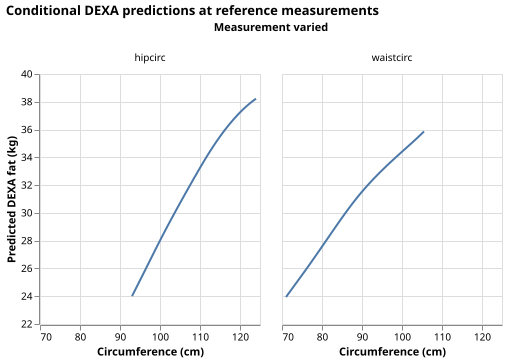

In [10]:
reference = {name: train[name].median() for name in ("age", "waistcirc", "hipcirc")}
frames = []
for name in ("waistcirc", "hipcirc"):
    values = np.linspace(train[name].quantile(.1), train[name].quantile(.9), 60)
    frame = pl.DataFrame({key: np.repeat(value, 60) for key, value in reference.items()})
    frames.append(frame.with_columns(pl.Series(name, values),
                                    pl.Series("circumference", values), pl.lit(name).alias("varied")))
grid = pl.concat(frames)
curves = grid.with_columns(pl.Series(
    "prediction", search.model.predict(grid.drop("circumference", "varied"), type="response"),
))
chart = alt.Chart(curves).mark_line().encode(
    x=alt.X("circumference:Q", title="Circumference (cm)", scale=alt.Scale(zero=False)),
    y=alt.Y("prediction:Q", title="Predicted DEXA fat (kg)", scale=alt.Scale(zero=False)),
    column=alt.Column("varied:N", title="Measurement varied"),
).properties(title="Conditional DEXA predictions at reference measurements", width=220, height=250)
display(chart)

Both reference slices increase: larger hip and waist measurements correspond
to higher predicted fat mass when the other measurements are held fixed. Their directions and sizes describe this fitted
association; the analysis provides no intervention effect or post-selection
confidence interval.

## Extension: live LLM judgments

`LLMJudge` sends the evidence digest and supplied domain context to the configured
chat endpoint. To run a live extension, set the three environment variables below
and replace the demonstration callback with this judge. The block is not
executed on this page: it requires credentials, incurs provider charges and
produces different proposals on each run. The results on this page make no claim
about the reasoning performance of a language model.

```python
import os

judge = mb.LLMJudge(
    llm=os.environ["MBOOSTRS_JUDGE_MODEL"],
    base_url=os.environ["MBOOSTRS_JUDGE_URL"],
    api_key=os.environ["MBOOSTRS_JUDGE_KEY"],
    max_calls=2, max_total_tokens=6000, max_tokens=1200,
)
live = mb.modeler_loop(
    train, "DEXfat", family=mb.Gaussian(), judgment=judge,
    domain_context="Predict DEXA fat from age and circumferences; associations only.",
    locks=("waistcirc",), budget=30, max_rounds=2, seed=4,
    mstop=100, tune_start=100, preexploration="dual",
    workflow_budget=mb.CostBudget(fits=500),
)
provider_audit = judge.calls
search_audit = live.to_dict()
```

`max_calls` bounds provider requests. `max_total_tokens` is checked between
requests using reported usage, so the final request can exceed it; missing usage
prevents another request under this limit. Call records include provider/model
identity, prompt and reply hashes, usage when available, and failures. Keep test
rows out of both the training frame and the domain context. If the provider fails
or emits an invalid proposal, the deterministic search remains available.
For argument details and scope limitations see [](../usage/specification_search.ipynb).

The paired-search calculation and its evaluation boundary are derived in
[](../methodology/search_decisions.ipynb).